# BTL01: XẤP XỈ HÀM MẬT ĐỘ GAUSSIAN 2 CHIỀU BẰNG MẠNG MLP (PYTORCH)
**Môn học:** Deep Learning (Học sâu)  
**Thành viên 1:** Quản lý Dữ liệu, Mô hình PyTorch & Thực nghiệm A (Quy mô dữ liệu)

---
### Mục tiêu Notebook:
1. Sinh dữ liệu hàm mật độ Gaussian 2 chiều chính xác theo đề bài:
   $$\boldsymbol{\mu} = \begin{bmatrix} 0 \\ 0 \end{bmatrix}, \quad C = \begin{bmatrix} 0.3 & -0.5 \\ -0.5 & 2.0 \end{bmatrix}, \quad x_1 \in [-2, 2], \; x_2 \in [-4, 4]$$
2. Khảo sát phân bố dữ liệu và trực quan hóa 3D.
3. Xây dựng mạng `FlexibleMLP` bằng PyTorch (`torch.nn.Module`).
4. Tiến hành **Thực nghiệm A**: Đánh giá tác động của quy mô dữ liệu $A \in [200, 2000]$ với $\ge 3$ random seeds.
5. Xuất bảng thống kê $\text{Mean} \pm \text{Std}$ và các đồ thị phục vụ Báo cáo & Slide.

In [1]:
# 1. Khai báo thư viện và cấu hình hiển thị đồ thị inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Import các module tự xây dựng từ thư mục src/
from src.dataset import Gaussian2D, generate_dataset, create_data_splits, load_dataset_from_csv, GaussianDataset
from src.model import FlexibleMLP
from src.trainer import Trainer
from src.evaluate import evaluate_model, compute_metrics
from src.plot_utils import plot_3d_scatter, plot_true_surface, plot_loss_curves, plot_comparison_surface, plot_experiment_a

# Kiểm tra phần cứng
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[*] Đang sử dụng thiết bị: {device}")
print(f"[*] PyTorch Version: {torch.__version__}")

[*] Đang sử dụng thiết bị: cpu
[*] PyTorch Version: 2.14.0+cpu


## 1. Sinh Dữ liệu & Trực quan hóa Khảo sát (EDA)
Sinh độc lập 3 tập dữ liệu để chống rò rỉ dữ liệu (data leakage):
- **Test set:** 100 mẫu (cố định để kiểm thử cuối cùng).
- **Validation set:** 400 mẫu (dùng chọn checkpoint mô hình tốt nhất).
- **Training Pool:** 2000 mẫu (trích xuất các tập con cho Thực nghiệm A).

In [2]:
# Sinh dữ liệu và lưu ra các file CSV
splits = create_data_splits(train_pool_size=2000, val_size=400, test_size=100, base_seed=42, data_dir="data")
X_pool, y_pool = splits["train_pool"]
X_val, y_val = splits["val"]
X_test, y_test = splits["test"]

# Hiển thị thống kê mô tả
df_stats = pd.DataFrame({"x1": X_pool[:, 0], "x2": X_pool[:, 1], "y": y_pool[:, 0]})
display(df_stats.describe().T[["count", "mean", "std", "min", "50%", "max"]])

Đã lưu 100 mẫu vào: data\test.csv
Đã lưu 400 mẫu vào: data\val.csv
Đã lưu 2000 mẫu vào: data\train_pool_2000.csv


,count,mean,std,min,50%,max
x1,2000.0,0.056938,1.163425,-1.993105e+00,0.115521,1.998091
x2,2000.0,0.011547,2.322864,-3.999658e+00,0.015565,3.995051
y,2000.0,0.029555,0.054935,8.833284e-14,0.003631,0.268164


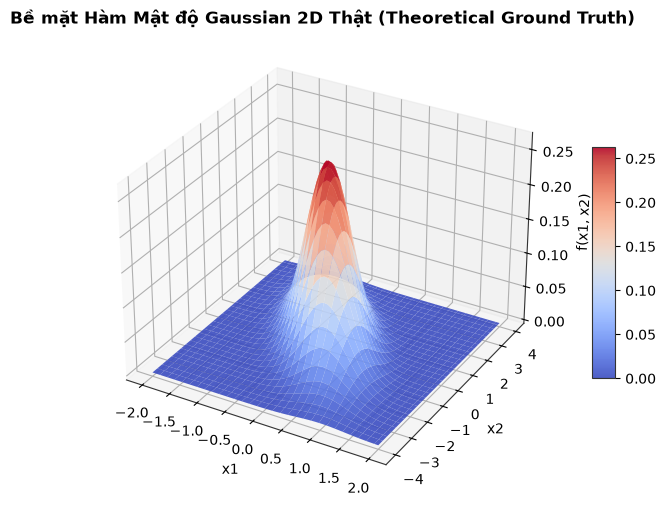

In [3]:
# Trực quan hóa Bề mặt hàm Gaussian thật (Ground Truth)
gaussian_fn = Gaussian2D()

x1_grid = np.linspace(-2.0, 2.0, 60)
x2_grid = np.linspace(-4.0, 4.0, 60)
X1, X2 = np.meshgrid(x1_grid, x2_grid)
points = np.vstack([X1.ravel(), X2.ravel()]).T
Y_grid = gaussian_fn(points).reshape(60, 60)

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X1, X2, Y_grid, cmap="coolwarm", edgecolor="none", alpha=0.9)
ax.set_title("Bề mặt Hàm Mật độ Gaussian 2D Thật (Theoretical Ground Truth)", fontsize=12, fontweight="bold")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("f(x1, x2)")
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.show()

## 2. Khởi tạo Kiến trúc Mạng Perceptron Đa Tầng (MLP)
Sử dụng class `FlexibleMLP(torch.nn.Module)` tùy biến được số tầng ẩn và số nơ-ron.

In [4]:
# Khởi tạo mô hình mẫu: 1 tầng ẩn, 128 nơ-ron, hàm kích hoạt Tanh
sample_model = FlexibleMLP(input_dim=2, hidden_dims=[128], output_dim=1, activation="tanh")
print(sample_model)
print(f"-> Tổng số tham số có thể huấn luyện: {sample_model.count_parameters()}")

FlexibleMLP(hidden_dims=[128], activation='tanh', total_params=513)
-> Tổng số tham số có thể huấn luyện: 513


## 3. Thực nghiệm A: Đánh giá Tác động của Quy mô Dữ liệu Huấn luyện (A)
- Khảo sát $A \in [200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000]$.
- Lặp lại 3 random seeds: [42, 123, 999] để tính $\text{Mean} \pm \text{Std}$.

In [5]:
# Nạp bảng kết quả thực nghiệm đã chạy và lưu sẵn
summary_path = "logs/exp_A_summary.csv"

if os.path.exists(summary_path):
    df_summary = pd.read_csv(summary_path)
    display_df = df_summary.copy()
    display_df["Test MSE (Mean ± Std)"] = display_df.apply(lambda r: f"{r['mse_mean']:.6f} ± {r['mse_std']:.6f}", axis=1)
    display_df["Test MAE (Mean ± Std)"] = display_df.apply(lambda r: f"{r['mae_mean']:.6f} ± {r['mae_std']:.6f}", axis=1)
    display_df["R2"] = display_df["r2_mean"].apply(lambda v: f"{v:.4f}")
    display_df["Time (s)"] = display_df["time_mean"].apply(lambda v: f"{v:.2f}")
    
    print("=== BẢNG KẾT QUẢ THỰC NGHIỆM A (CHÈN VÀO BÁO CÁO) ===")
    display(display_df[["size", "Test MSE (Mean ± Std)", "Test MAE (Mean ± Std)", "R2", "Time (s)"]])
else:
    print("Chưa có file log. Vui lòng chạy lệnh: python exp_A_datasize.py trên terminal.")

=== BẢNG KẾT QUẢ THỰC NGHIỆM A (CHÈN VÀO BÁO CÁO) ===


,size,Test MSE (Mean ± Std),Test MAE (Mean ± Std),R2,Time (s)
0,200,0.002610 ± 0.000163,0.035792 ± 0.002113,0.2681,5.44
1,400,0.001499 ± 0.000369,0.028456 ± 0.003318,0.5798,14.37
2,600,0.001143 ± 0.000136,0.025219 ± 0.000425,0.6794,7.84
3,800,0.000998 ± 0.000109,0.022989 ± 0.001747,0.7201,9.94
4,1000,0.000723 ± 0.000102,0.020319 ± 0.001190,0.7972,12.79
5,1200,0.000716 ± 0.000098,0.020111 ± 0.001743,0.7992,13.17
6,1400,0.000752 ± 0.000113,0.021879 ± 0.002038,0.7892,15.92
7,1600,0.000570 ± 0.000099,0.017957 ± 0.001092,0.8403,16.01
8,1800,0.000522 ± 0.000083,0.017517 ± 0.001858,0.8537,21.62
9,2000,0.000465 ± 0.000135,0.017201 ± 0.002398,0.8696,16.12


## 4. Biểu đồ Sai số & Đánh giá Bề mặt Xấp xỉ

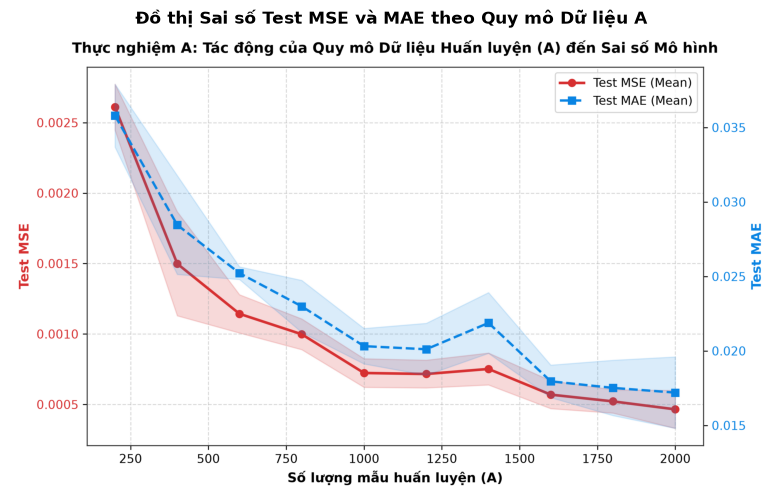

In [6]:
# Hiển thị đồ thị sai số theo quy mô A
fig_err = plt.imread("figures/exp_A_error_vs_size.png")
plt.figure(figsize=(10, 6))
plt.imshow(fig_err)
plt.axis("off")
plt.title("Đồ thị Sai số Test MSE và MAE theo Quy mô Dữ liệu A", fontsize=12, fontweight="bold")
plt.show()

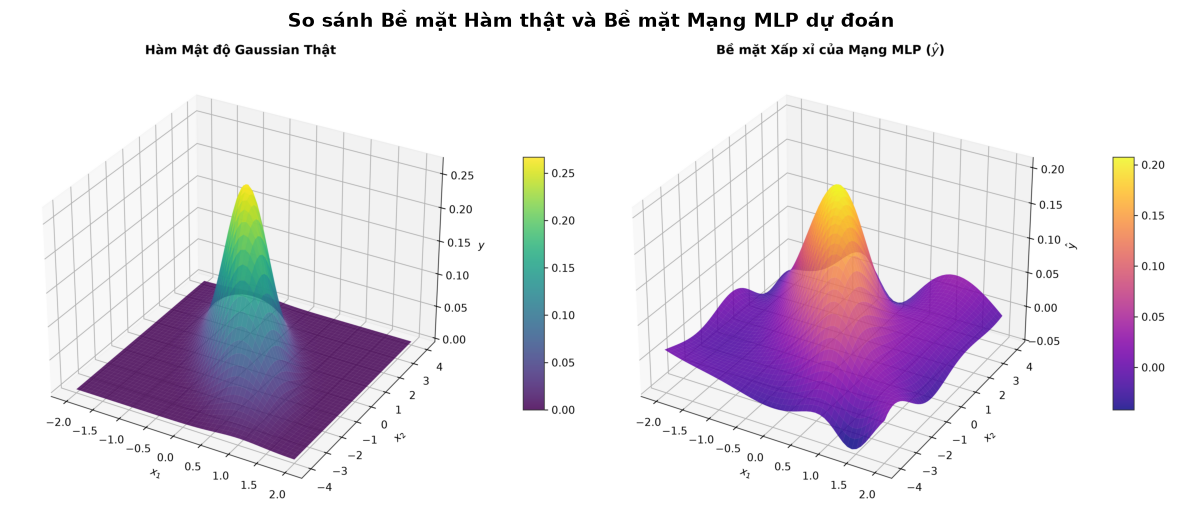

In [7]:
# Hiển thị so sánh 2 bề mặt 3D: Hàm thật vs MLP xấp xỉ
fig_surf = plt.imread("figures/exp_A_surface_comparison.png")
plt.figure(figsize=(15, 7))
plt.imshow(fig_surf)
plt.axis("off")
plt.title("So sánh Bề mặt Hàm thật và Bề mặt Mạng MLP dự đoán", fontsize=14, fontweight="bold")
plt.show()